### Base simulation:
- Activate only one source dipole $\rightarrow$ $x_{1,t} = A \text{sin}(2\pi t)$
- Forward using the tutorial ```30_forward.ipynb```
- Produce output with the model: $Y = LX +E$, where $E_{n,t} \sim \text{N}(0, \sigma^2)$
- Check metrics of the result:
    - $||X-\hat{X}||_{F}$
    - $\text{F}_{1}$-score on activation

1. Obtaining the matrix L (A of the model) from mne

In [ ]:
import mne
import numpy as np
#import pyvista
#pyvista.set_jupyter_backend(None)

In [52]:
montage = mne.channels.make_standard_montage("colin27_1020")
chs = [c for c in montage.ch_names if c not in ["T3", "T4", "T5", "T6"]]
info = mne.create_info(chs, sfreq=250.0, ch_types="eeg")
info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fpz, Fp2, AF9, AF7, AF5, AF3, AF1, AFz, AF2, AF4, AF6, AF8, ...
 chs: 90 EEG
 custom_ref_applied: False
 dig: 93 items (3 Cardinal, 90 EEG)
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: unspecified
 nchan: 90
 projs: []
 sfreq: 250.0 Hz
>

In [53]:
sphere = mne.make_sphere_model(r0="auto", head_radius="auto", info=info)
src = mne.setup_volume_source_space(
    sphere=sphere, pos=15.0, exclude=30.0, add_interpolator=False
)

Fitted sphere radius:         99.1 mm
Origin head coordinates:      -1.0 13.8 38.3 mm
Origin device coordinates:    -1.0 13.8 38.3 mm

Equiv. model fitting -> RV = 0.00347616 %%
mu1 = 0.944836    lambda1 = 0.136856
mu2 = 0.66776    lambda2 = 0.683695
mu3 = -0.291317    lambda3 = -0.0101806
Set up EEG sphere model with scalp radius    99.1 mm

Sphere                : origin at (-1.0 13.8 38.3) mm
              radius  : 89.2 mm
grid                  : 15.0 mm
mindist               : 5.0 mm
Exclude               : 30.0 mm

Setting up the sphere...
Surface CM = (  -1.0   13.8   38.3) mm
Surface fits inside a sphere with radius   89.2 mm
Surface extent:
    x =  -90.1 ...   88.2 mm
    y =  -75.3 ...  103.0 mm
    z =  -50.9 ...  127.4 mm
Grid extent:
    x = -105.0 ...   90.0 mm
    y =  -90.0 ...  105.0 mm
    z =  -60.0 ...  135.0 mm
2744 sources before omitting any.
840 sources after omitting infeasible sources not within 30.0 - 89.2 mm.
Source spaces are in MRI coordinates.
Checking t

In [54]:
fwd = mne.make_forward_solution(
    info, trans=None, src=src, bem=sphere, meg=False, eeg=True, mindist=5.0
)
L = fwd["sol"]["data"]

Source space          : <SourceSpaces: [<discrete, n_used=710>] MRI (surface RAS) coords, ~698 KiB>
MRI -> head transform : identity
Measurement data      : instance of Info
Sphere model      : origin at [-0.0009528   0.01381019  0.03826742] mm
Standard field computations
Do computations in head coordinates
Free source orientations

Read 1 source spaces a total of 710 active source locations

Coordinate transformation: MRI (surface RAS) -> head
    1.000000 0.000000 0.000000       0.00 mm
    0.000000 1.000000 0.000000       0.00 mm
    0.000000 0.000000 1.000000       0.00 mm
    0.000000 0.000000 0.000000       1.00

Read  90 EEG channels from info
Head coordinate coil definitions created.
Source spaces are now in head coordinates.

Using the sphere model.

Source spaces are in head coordinates.
Checking that the sources are inside the surface and at least    5.0 mm away (will take a few...)
Using the equivalent source approach in the homogeneous sphere for EEG
Computing EEG at 710 s

2. Set up the small simulation with only $x_1$ activated.

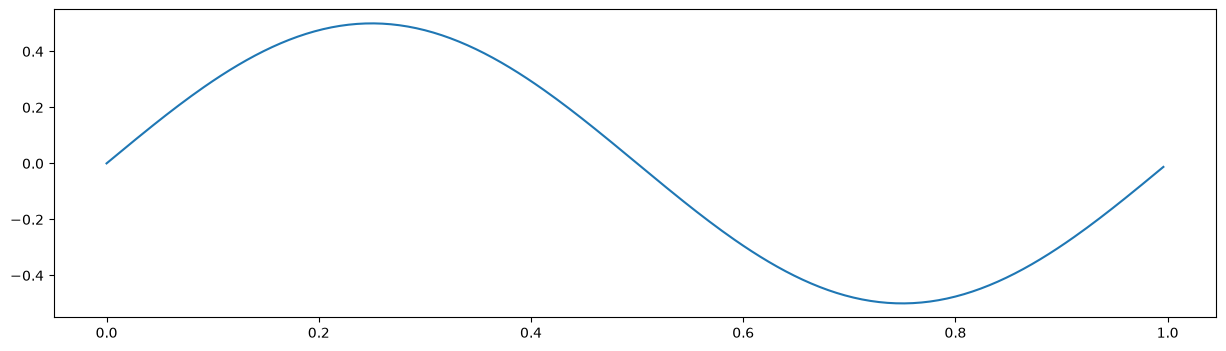

In [55]:
t = np.linspace(0, 1, int(info["sfreq"]), endpoint=False)
A = 0.5

# Signal of the first dipole
x_1 = A * np.sin(2 * np.pi * t)
X = np.zeros((L.shape[1], int(info["sfreq"])))
X[0] = x_1

# Plot the signal
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 4))
plt.plot(t, x_1)

3. "Forward" of the signal.

In [56]:
beta = 4
e = np.random.normal(0, np.sqrt(1/beta), size=(L.shape[0], int(info["sfreq"])))

Y = L @ X + e

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


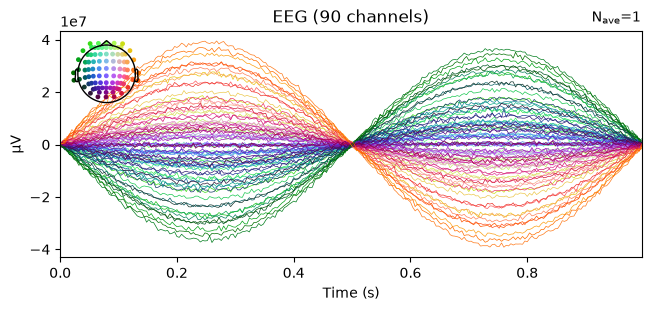

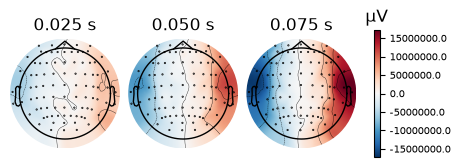

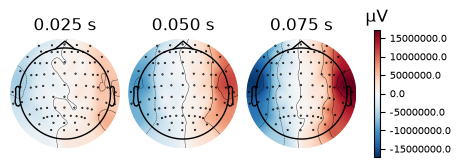

In [57]:
evoked = mne.EvokedArray(Y, info, tmin=0.0)
evoked.set_eeg_reference("average", projection=False)   # referencia promedio
evoked.plot(spatial_colors=True)
evoked.plot_topomap(times=[0.025, 0.05, 0.075])

4. Calculation and plot of the inverse solution using mne.

$x_j \sim \mathcal{N}(x_j|0, \alpha^{-1}), \alpha \in \mathbb{R}$

$p(\textbf{x}|\alpha) = \prod_{k=1}^{D}\mathcal{N}(x_k|\textbf{0}, \alpha^{-1}\textbf{I})$

$p(\textbf{y}|x) = \prod_{k=1}^{D}\mathcal{N}(y_k|Lx_k, \beta^{-1}\textbf{I})$

$\Gamma = \alpha^{-1}\textbf{I} + \beta L^TL$

$\hat{x}_k = \beta \Gamma^{-1}L^Ty_k$

In [ ]:
alpha = 1.0
Gamma = alpha * np.eye(L.shape[1]) + beta * L.T @ L
x_hat = beta * np.linalg.solve(Gamma, L.T @ Y)

5. Plot and compute metrics

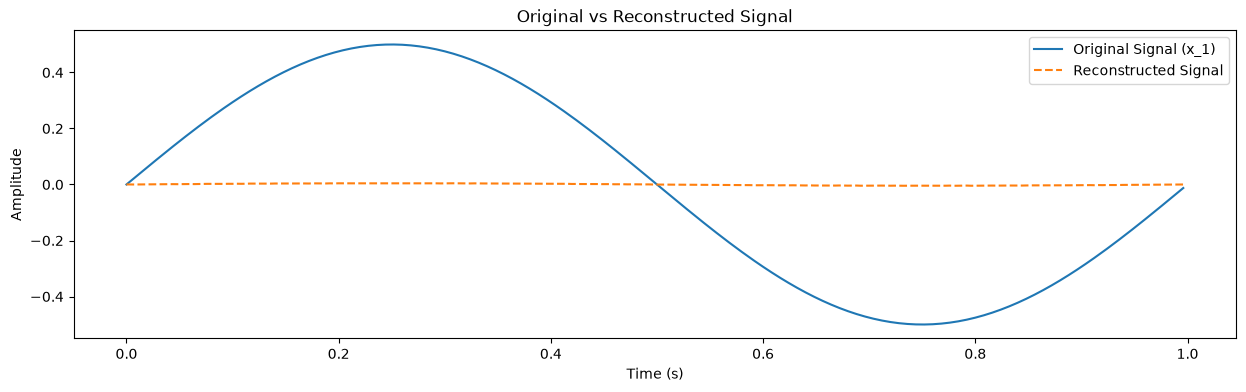

In [59]:
reconstructed = x_hat[0]

# Plot the original x_1 and the reconstructed signal
plt.figure(figsize=(15, 4))
plt.plot(t, x_1, label="Original Signal (x_1)")
plt.plot(t, reconstructed, label="Reconstructed Signal", linestyle='--')
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original vs Reconstructed Signal")
plt.legend()

In [60]:
print(np.linalg.norm(x_hat - X))

5.574115915352642


In [61]:
n_loc = x_hat.shape[0] // 3   # 710
x_hat_loc = x_hat.reshape(n_loc, 3, -1)          # (710, 3, 250)
norms = np.linalg.norm(x_hat_loc, axis=(1, 2))   # (710,) — one norm per location

In [62]:
X_loc = X.reshape(n_loc, 3, -1)              # (710, 3, 250)
norms_true = np.linalg.norm(X_loc, axis=(1, 2))
center = sphere['r0']            
pos = src[0]['rr'][src[0]['vertno']]

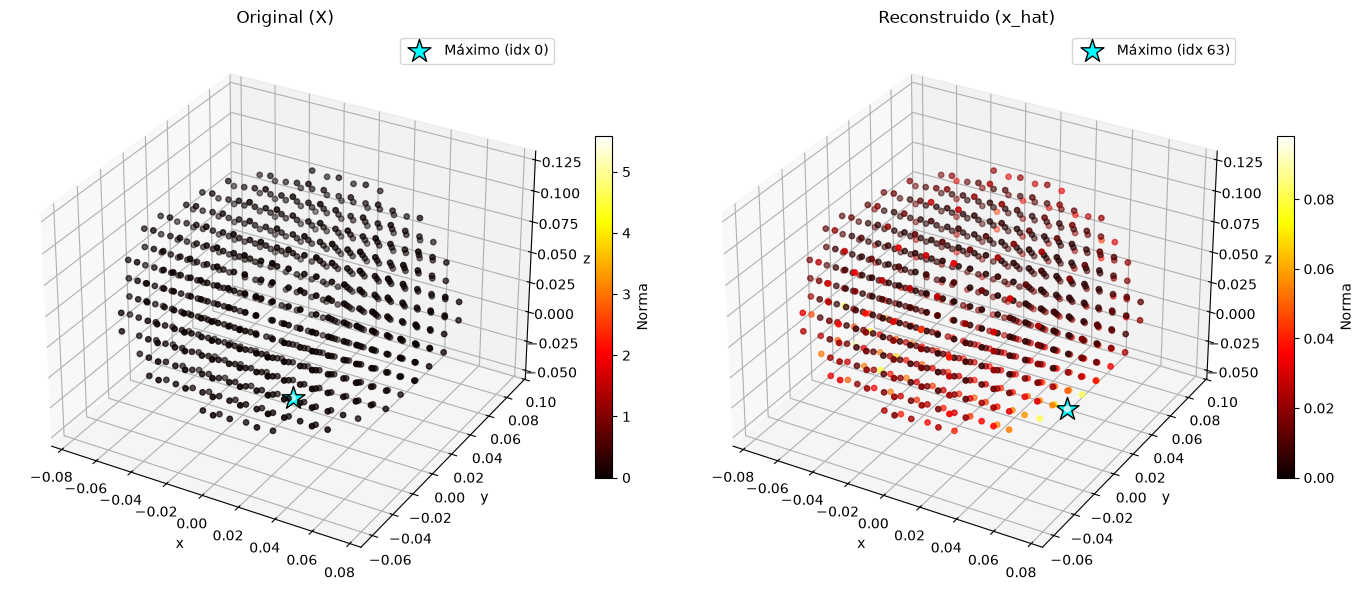

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw={'projection': '3d'})

datasets = [
    (norms_true, 'Original (X)'),
    (norms,      'Reconstructed (x_hat)'),
]

for ax, (data, title) in zip(axes, datasets):
    sc = ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2],
                     c=data, cmap='hot', s=15,
                     vmin=0, vmax=data.max())

    # 2. Star on the maximum value
    idx = data.argmax()
    ax.scatter(*pos[idx], color='cyan', s=300, marker='*',
               edgecolor='black', linewidth=1, zorder=10,
               label=f'Max (idx {idx})')

    ax.set_title(title)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.legend()
    plt.colorbar(sc, ax=ax, label='Norma', shrink=0.6)

plt.tight_layout()
plt.show()

In [64]:
# 1. Evoked with projection
evoked = mne.EvokedArray(Y, info, tmin=0.0)
evoked.set_eeg_reference("average", projection=True)     # projection=True, no False

# 2. Covariance of the noise 
noise_cov = mne.make_ad_hoc_cov(evoked.info, std=dict(eeg=beta))

# 3. Inverse operator
inverse_operator = mne.minimum_norm.make_inverse_operator(
    evoked.info, fwd, noise_cov, loose=1.0, depth=0.8
)

# 4. Solve the inverse problem
method = "sLORETA"            # o "eLORETA", "dSPM", "MNE"
#snr= Var(LX)/Var(e)
snr = np.var(L@X) / beta**2
lambda2 = 1.0 / snr
stc = mne.minimum_norm.apply_inverse(evoked, inverse_operator, lambda2, method=method, pick_ori="vector")

print(stc.data)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Computing inverse operator with 90 channels.
    90 out of 90 channels remain after picking
Selected 90 channels
Creating the depth weighting matrix...
    90 EEG channels
    limit = 711/710 = 3.632519
    scale = 98027.3 exp = 0.8
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 0.0032 (2.2e-16 eps * 90 dim * 1.6e+11  max singular value)
    Estimated rank (eeg): 89
    EEG: rank 89 computed from 90 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 5.10657
    scaling